## 0. Setup

In [1]:
import os, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)
from mlxtend.frequent_patterns import apriori, association_rules

warnings.filterwarnings("ignore")
os.makedirs("plots", exist_ok=True)
os.makedirs("processed_data", exist_ok=True)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight"})
RANDOM_STATE = 42
OCC_LABELS = {0: "Unoccupied", 1: "Occupied"}

def save(name):
    plt.savefig(f"plots/{name}.png")

## 1. Load data & descriptive statistics

In [2]:
def load(path):
    df = pd.read_csv(path, index_col=0)
    df["date"] = pd.to_datetime(df["date"])
    return df

train_raw = load("datatraining.txt")
test1_raw = load("datatest.txt")
test2_raw = load("datatest2.txt")

for name, d in [("Train (datatraining.txt)", train_raw), ("Test-1 (datatest.txt)", test1_raw), ("Test-2 (datatest2.txt)", test2_raw)]:
    print(f"{name:26s} rows={len(d):5d}  period={d['date'].min()} -> {d['date'].max()}  occupied={d['Occupancy'].mean():.1%}")

print("\nFirst rows of training data:")
display(train_raw.head())
print("Descriptive statistics (training):")
display(train_raw.describe().T.round(4))

Train (datatraining.txt)   rows= 8143  period=2015-02-04 17:51:00 -> 2015-02-10 09:33:00  occupied=21.2%
Test-1 (datatest.txt)      rows= 2665  period=2015-02-02 14:19:00 -> 2015-02-04 10:43:00  occupied=36.5%
Test-2 (datatest2.txt)     rows= 9752  period=2015-02-11 14:48:00 -> 2015-02-18 09:19:00  occupied=21.0%

First rows of training data:


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
1,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1
2,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1
3,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1
4,2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1
5,2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1


Descriptive statistics (training):


,count,mean,min,25%,50%,75%,max,std
date,8143,2015-02-07 13:41:59.688812544,2015-02-04 17:51:00,2015-02-06 03:46:30,2015-02-07 13:41:59,2015-02-08 23:37:30,2015-02-10 09:33:00,NaN
Temperature,8143.0,20.619084,19.0,19.7,20.39,21.39,23.18,1.016916
Humidity,8143.0,25.731507,16.745,20.2,26.2225,30.533333,39.1175,5.531211
Light,8143.0,119.519375,0.0,0.0,0.0,256.375,1546.333333,194.755805
CO2,8143.0,606.546243,412.75,439.0,453.5,638.833333,2028.5,314.320877
HumidityRatio,8143.0,0.003863,0.002674,0.003078,0.003801,0.004352,0.006476,0.000852
Occupancy,8143.0,0.21233,0.0,0.0,0.0,0.0,1.0,0.408982


## 2. Data Preprocessing
### 2.1 Cleaning — remove noisy / invalid data
Steps: missing values → duplicates → sort / duplicated time-stamps → **physical-validity rules** → outlier *diagnosis* (IQR).

Decision on outliers: the IQR rule flags many high CO2 and Light readings, but these are **genuine occupancy signals** (people exhaling CO2, lights on), not sensor noise. Clipping them would erase the signal and make training / test distributions differ, so they are *kept*; only physically impossible readings are removed.

In [3]:
SENSORS = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio"]

# Physically plausible ranges for an indoor office sensor node
VALID = {"Temperature": (10, 40), "Humidity": (0, 100), "Light": (0, 5000),
         "CO2": (300, 5000), "HumidityRatio": (0, 0.05)}

def clean(df, name):
    n0 = len(df)
    df = df.copy()
    n_missing = int(df.isnull().sum().sum())
    df = df.dropna()
    n_dup = int(df.duplicated().sum())
    df = df.drop_duplicates()
    n_dup_ts = int(df["date"].duplicated().sum())
    df = df.drop_duplicates(subset="date", keep="first")
    df = df.sort_values("date")
    mask_valid = pd.Series(True, index=df.index)
    for c, (lo, hi) in VALID.items():
        mask_valid &= df[c].between(lo, hi)
    mask_valid &= df["Occupancy"].isin([0, 1])
    n_invalid = int((~mask_valid).sum())
    df = df[mask_valid]
    print(f"{name:7s}: rows {n0} -> {len(df)} | missing={n_missing} duplicates={n_dup} duplicate-timestamps={n_dup_ts} invalid-range={n_invalid}")
    return df

train = clean(train_raw, "Train")
test1 = clean(test1_raw, "Test-1")
test2 = clean(test2_raw, "Test-2")

# Outlier DIAGNOSIS (not removal) using the 1.5*IQR rule on training data
rows = []
for c in SENSORS:
    q1, q3 = train[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flag = (train[c] < lo) | (train[c] > hi)
    rows.append({"Feature": c, "IQR lower": round(lo, 4), "IQR upper": round(hi, 4),
                 "Flagged rows": int(flag.sum()), "Flagged %": round(100 * flag.mean(), 2),
                 "Occupied among flagged %": round(100 * train.loc[flag, "Occupancy"].mean(), 1) if flag.any() else np.nan})
print("\nIQR outlier diagnosis (training set):")
display(pd.DataFrame(rows).set_index("Feature"))
print("Interpretation: flagged CO2 / Light rows are mostly OCCUPIED rows -> genuine signal, kept (no clipping).")

# Gap check: are the readings roughly one-per-minute?
gaps = train["date"].diff().dt.total_seconds().div(60).dropna()
print(f"\nSampling interval (min): median={gaps.median():.2f}, max gap={gaps.max():.1f} min")

Train  : rows 8143 -> 8143 | missing=0 duplicates=0 duplicate-timestamps=0 invalid-range=0
Test-1 : rows 2665 -> 2665 | missing=0 duplicates=0 duplicate-timestamps=0 invalid-range=0
Test-2 : rows 9752 -> 9752 | missing=0 duplicates=0 duplicate-timestamps=0 invalid-range=0

IQR outlier diagnosis (training set):


,IQR lower,IQR upper,Flagged rows,Flagged %,Occupied among flagged %
Feature,,,,,
Temperature,17.1650,23.9250,0,0.00,NaN
Humidity,4.7000,46.0333,0,0.00,NaN
Light,-384.5625,640.9375,15,0.18,73.3
CO2,139.2500,938.5833,1063,13.05,81.8
HumidityRatio,0.0012,0.0063,118,1.45,100.0


Interpretation: flagged CO2 / Light rows are mostly OCCUPIED rows -> genuine signal, kept (no clipping).

Sampling interval (min): median=1.00, max gap=1.0 min


### 2.2 Data selection — task-relevant attributes
Evidence used (all from the **training set only**): Pearson correlation with the target, mutual information, multicollinearity (VIF), and an exhaustive subset search scored by **day-grouped cross-validation** with a small decision tree.

In [4]:
corr = train[SENSORS + ["Occupancy"]].corr()
mi = pd.Series(mutual_info_classif(train[SENSORS], train["Occupancy"], random_state=RANDOM_STATE), index=SENSORS)

def vif(df, cols):
    out = {}
    for c in cols:
        others = [x for x in cols if x != c]
        r2 = LinearRegression().fit(df[others], df[c]).score(df[others], df[c])
        out[c] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out)

summary = pd.DataFrame({
    "Corr with Occupancy": corr["Occupancy"].drop("Occupancy"),
    "|Corr|": corr["Occupancy"].drop("Occupancy").abs(),
    "Mutual information": mi,
    "VIF (all 5 sensors)": vif(train, SENSORS),
}).sort_values("|Corr|", ascending=False).round(4)
print("--- Feature relevance & redundancy ---")
display(summary)
print(f"Humidity vs HumidityRatio correlation r = {corr.loc['Humidity','HumidityRatio']:.4f}  "
      f"(HumidityRatio is a deterministic function of Temperature & Humidity -> redundant)")

--- Feature relevance & redundancy ---


,Corr with Occupancy,|Corr|,Mutual information,VIF (all 5 sensors)
Light,0.9074,0.9074,0.4745,2.7809
CO2,0.7122,0.7122,0.3444,6.6918
Temperature,0.5382,0.5382,0.2247,45.0501
HumidityRatio,0.3003,0.3003,0.2519,617.9702
Humidity,0.1330,0.1330,0.1944,571.6902


Humidity vs HumidityRatio correlation r = 0.9552  (HumidityRatio is a deterministic function of Temperature & Humidity -> redundant)


In [5]:
# Exhaustive subset search with day-grouped CV (training data only)
train["Hour"] = train["date"].dt.hour
groups = train["date"].dt.date.astype(str)
cv = GroupKFold(n_splits=groups.nunique())       # leave-one-day-out
CANDIDATES = ["Temperature", "Humidity", "Light", "CO2", "Hour"]   # HumidityRatio already dropped (redundant)

def cv_scores(features, **tree_kw):
    model = DecisionTreeClassifier(random_state=RANDOM_STATE, **tree_kw)
    pred = cross_val_predict(model, train[features], train["Occupancy"], groups=groups, cv=cv)
    return f1_score(train["Occupancy"], pred), accuracy_score(train["Occupancy"], pred)

res = []
for k in range(1, len(CANDIDATES) + 1):
    for fs in itertools.combinations(CANDIDATES, k):
        f1, acc = cv_scores(list(fs), max_depth=3)
        res.append({"Features": " + ".join(fs), "CV F1": round(f1, 4), "CV Accuracy": round(acc, 4)})
subset_df = pd.DataFrame(res).sort_values("CV F1", ascending=False).reset_index(drop=True)
print("--- Top 10 feature subsets (leave-one-day-out CV, depth-3 tree, training data only) ---")
display(subset_df.head(10))

--- Top 10 feature subsets (leave-one-day-out CV, depth-3 tree, training data only) ---


,Features,CV F1,CV Accuracy
0,Light + Hour,0.9436,0.9749
1,Light,0.9424,0.9745
2,CO2 + Hour,0.9377,0.9729
3,Temperature + Light + Hour,0.9342,0.9708
4,Temperature + Humidity + Light,0.9274,0.9687
5,Temperature + Humidity + Light + Hour,0.9274,0.9687
6,Humidity + Light,0.9259,0.9677
7,Humidity + Light + Hour,0.9259,0.9677
8,Temperature + Light,0.9237,0.9657
9,Temperature + CO2 + Hour,0.9187,0.9639


In [6]:
SELECTED = ["Light", "CO2"]
r_light, r_co2 = corr.loc["Light", "Occupancy"], corr.loc["CO2", "Occupancy"]
hour_gain = subset_df.loc[subset_df["Features"] == "Light + Hour", "CV F1"].iloc[0] - subset_df.loc[subset_df["Features"] == "Light", "CV F1"].iloc[0]
print("SELECTED FEATURES FOR CLASSIFICATION:", SELECTED)
print(f"""
Justification (all numbers from the training set)
 * Light (r={r_light:.2f}) and CO2 (r={r_co2:.2f}) are the two strongest relevant attributes (also top-2 by mutual information).
 * HumidityRatio is DROPPED: r=0.96 with Humidity, VIF > 500, and it is computed from Temperature & Humidity.
 * Temperature / Humidity are dropped: every subset containing them has a LOWER leave-one-day-out CV F1 than Light-based subsets
   (they follow the room's heating schedule, not occupancy itself, and generalise poorly to other days).
 * Hour adds only {hour_gain:+.4f} CV-F1 (negligible) and makes the model depend on a fixed working schedule -> excluded.
 * 'date' is dropped after feature extraction (identifier, not a predictor).
 * CO2 is kept as a candidate next to Light; Section 4.2 tunes the tree and reports which of the two it actually uses.
""")

SELECTED FEATURES FOR CLASSIFICATION: ['Light', 'CO2']

Justification (all numbers from the training set)
 * Light (r=0.91) and CO2 (r=0.71) are the two strongest relevant attributes (also top-2 by mutual information).
 * HumidityRatio is DROPPED: r=0.96 with Humidity, VIF > 500, and it is computed from Temperature & Humidity.
 * Temperature / Humidity are dropped: every subset containing them has a LOWER leave-one-day-out CV F1 than Light-based subsets
   (they follow the room's heating schedule, not occupancy itself, and generalise poorly to other days).
 * Hour adds only +0.0012 CV-F1 (negligible) and makes the model depend on a fixed working schedule -> excluded.
 * 'date' is dropped after feature extraction (identifier, not a predictor).
 * CO2 is kept as a candidate next to Light; Section 4.2 tunes the tree and reports which of the two it actually uses.



### 2.3 Data transformation — represent data in the form each task needs
* **Decision Tree:** numeric selected features (trees are scale-invariant, so no normalisation is required).
* **Apriori / A-CLOSE:** transactional (one-hot) data. Continuous sensors are **discretised**: Light with an entropy-based cut-point (off / dim / bright) learned on training data, CO2 with indoor-air-quality bands (600 and 1000 ppm), Temperature / Humidity into equal-frequency tertiles (learned on training), plus time-of-day and weekday/weekend derived from `date`. HumidityRatio is excluded (redundant).

In [7]:
for d in (train, test1, test2):
    d["Hour"] = d["date"].dt.hour
    d["DayOfWeek"] = d["date"].dt.dayofweek
    d["IsWeekend"] = (d["DayOfWeek"] >= 5).astype(int)

# ---- (a) numeric data for the Decision Tree
train.to_csv("processed_data/train_clean.csv", index=False)
test1.to_csv("processed_data/test1_clean.csv", index=False)
test2.to_csv("processed_data/test2_clean.csv", index=False)

# ---- (b) discretised transactions for Apriori / A-CLOSE
t_edges = train["Temperature"].quantile([0, 1/3, 2/3, 1]).to_numpy(copy=True); t_edges[0], t_edges[-1] = -np.inf, np.inf
h_edges = train["Humidity"].quantile([0, 1/3, 2/3, 1]).to_numpy(copy=True);    h_edges[0], h_edges[-1] = -np.inf, np.inf
# Supervised (entropy-based) discretisation of Light: best single split learned on TRAINING data only
light_cut = float(DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=RANDOM_STATE)
                  .fit(train[["Light"]], train["Occupancy"]).tree_.threshold[0])
print(f"Light cut-point learned by entropy stump: {light_cut:.1f} lux (0 = lights off)")
print(f"Temperature tertile edges: {np.round(t_edges[1:-1], 2)} degC | Humidity tertile edges: {np.round(h_edges[1:-1], 2)} %")

def to_transactions(df):
    a = pd.DataFrame(index=df.index)
    a["Light"] = pd.cut(df["Light"], [-np.inf, 0, light_cut, np.inf], labels=["Light_Off", "Light_Dim", "Light_Bright"])
    a["CO2"] = pd.cut(df["CO2"], [-np.inf, 600, 1000, np.inf], labels=["CO2_Low", "CO2_Moderate", "CO2_High"])
    a["Temp"] = pd.cut(df["Temperature"], t_edges, labels=["Temp_Cool", "Temp_Mild", "Temp_Warm"])
    a["Hum"] = pd.cut(df["Humidity"], h_edges, labels=["Hum_Dry", "Hum_Normal", "Hum_Humid"])
    a["Time"] = pd.cut(df["Hour"], [-1, 5, 11, 17, 23], labels=["Night", "Morning", "Afternoon", "Evening"])
    a["Day"] = np.where(df["IsWeekend"] == 1, "Weekend", "Weekday")
    a["Occ"] = df["Occupancy"].map(OCC_LABELS)
    return a

arm_df = to_transactions(train)
arm_df.to_csv("processed_data/train_for_arm.csv", index=False)
print("\nItem frequencies (share of transactions):")
display(pd.concat({c: arm_df[c].value_counts(normalize=True).round(3) for c in arm_df}, axis=0).to_frame("support"))
display(arm_df.head())

Light cut-point learned by entropy stump: 365.1 lux (0 = lights off)
Temperature tertile edges: [20. 21.] degC | Humidity tertile edges: [21.4 27.5] %

Item frequencies (share of transactions):


support
Light Light_Off       0.634
      Light_Bright    0.222
      Light_Dim       0.144
CO2   CO2_Low         0.735
      CO2_Moderate    0.145
      CO2_High        0.120
Temp  Temp_Cool       0.336
      Temp_Warm       0.333
      Temp_Mild       0.332
Hum   Hum_Normal      0.336
      Hum_Dry         0.333
      Hum_Humid       0.331
Time  Night           0.265
      Evening         0.265
      Morning         0.247
      Afternoon       0.222
Day   Weekday         0.646
      Weekend         0.354
Occ   Unoccupied      0.788
      Occupied        0.212

,Light,CO2,Temp,Hum,Time,Day,Occ
1,Light_Bright,CO2_Moderate,Temp_Warm,Hum_Normal,Afternoon,Weekday,Occupied
2,Light_Bright,CO2_Moderate,Temp_Warm,Hum_Normal,Afternoon,Weekday,Occupied
3,Light_Bright,CO2_Moderate,Temp_Warm,Hum_Normal,Afternoon,Weekday,Occupied
4,Light_Bright,CO2_Moderate,Temp_Warm,Hum_Normal,Afternoon,Weekday,Occupied
5,Light_Bright,CO2_Moderate,Temp_Warm,Hum_Normal,Afternoon,Weekday,Occupied


## 3. Visualisation (12 plots)

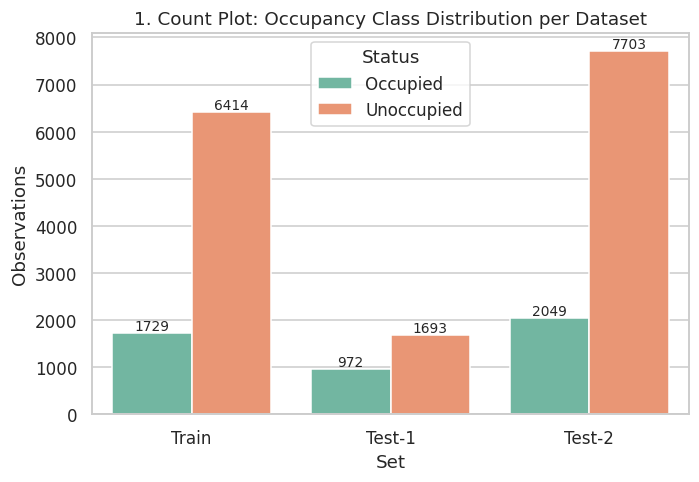

{'Test-1': '36.5% occupied', 'Test-2': '21.0% occupied', 'Train': '21.2% occupied'}


In [8]:
# Plot 1 — Count plot: class balance in each dataset
all_sets = pd.concat([train.assign(Set="Train"), test1.assign(Set="Test-1"), test2.assign(Set="Test-2")])
all_sets["Status"] = all_sets["Occupancy"].map(OCC_LABELS)
plt.figure(figsize=(7, 4.5))
ax = sns.countplot(data=all_sets, x="Set", hue="Status", palette="Set2")
for c in ax.containers: ax.bar_label(c, fontsize=9)
plt.title("1. Count Plot: Occupancy Class Distribution per Dataset"); plt.ylabel("Observations")
save("01_countplot_occupancy"); plt.show()
print({s: f"{g['Occupancy'].mean():.1%} occupied" for s, g in all_sets.groupby("Set")})

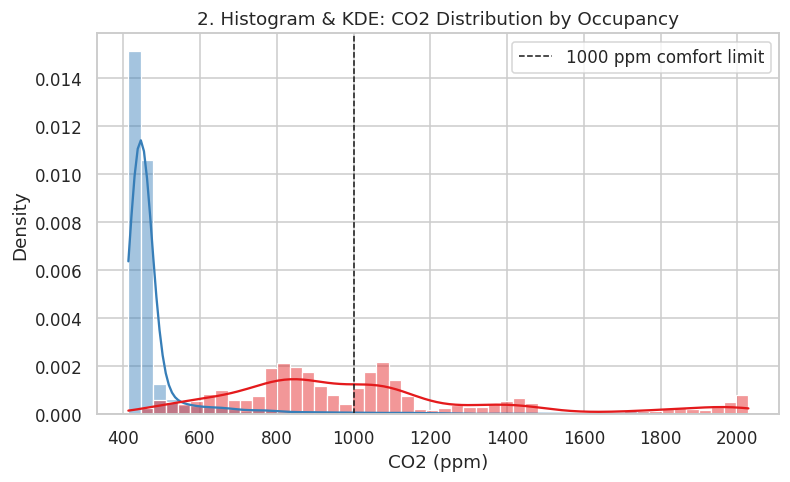

            count    mean    std    min    25%    50%     75%     max
Occupancy                                                            
0          6414.0   490.3  152.9  412.8  437.0  446.0   464.5  1784.5
1          1729.0  1037.7  377.6  439.0  796.0  944.0  1131.2  2028.5


In [9]:
# Plot 2 — Histogram + KDE: CO2 by occupancy
plt.figure(figsize=(8, 4.5))
sns.histplot(data=train.assign(Status=train["Occupancy"].map(OCC_LABELS)), x="CO2", hue="Status",
             bins=50, kde=True, stat="density", common_norm=False, palette="Set1", alpha=.45)
plt.axvline(1000, color="k", ls="--", lw=1, label="1000 ppm comfort limit"); plt.legend()
plt.title("2. Histogram & KDE: CO2 Distribution by Occupancy"); plt.xlabel("CO2 (ppm)")
save("02_histogram_co2"); plt.show()
print(train.groupby("Occupancy")["CO2"].describe().round(1))

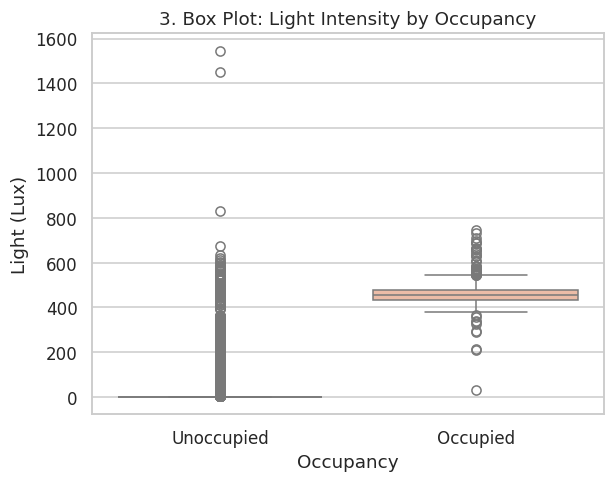

            count   mean   std   min    25%    50%    75%     max
Occupancy                                                        
0          6414.0   27.8  89.6   0.0    0.0    0.0    0.0  1546.3
1          1729.0  459.9  42.3  31.0  433.0  454.0  477.8   744.0


In [10]:
# Plot 3 — Box plot: Light by occupancy
plt.figure(figsize=(6, 4.5))
sns.boxplot(data=train, x="Occupancy", y="Light", hue="Occupancy", palette="coolwarm", legend=False)
plt.xticks([0, 1], ["Unoccupied", "Occupied"]); plt.ylabel("Light (Lux)")
plt.title("3. Box Plot: Light Intensity by Occupancy")
save("03_boxplot_light"); plt.show()
print(train.groupby("Occupancy")["Light"].describe().round(1))

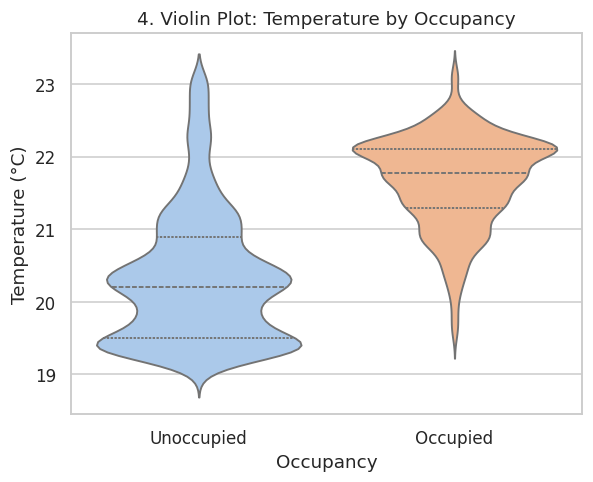

             mean  median    std
Occupancy                       
0          20.335  20.200  0.910
1          21.673  21.768  0.623


In [11]:
# Plot 4 — Violin plot: Temperature by occupancy
plt.figure(figsize=(6, 4.5))
sns.violinplot(data=train, x="Occupancy", y="Temperature", hue="Occupancy", palette="pastel", legend=False, inner="quartile")
plt.xticks([0, 1], ["Unoccupied", "Occupied"]); plt.ylabel("Temperature (°C)")
plt.title("4. Violin Plot: Temperature by Occupancy")
save("04_violinplot_temperature"); plt.show()
print(train.groupby("Occupancy")["Temperature"].agg(["mean", "median", "std"]).round(3))

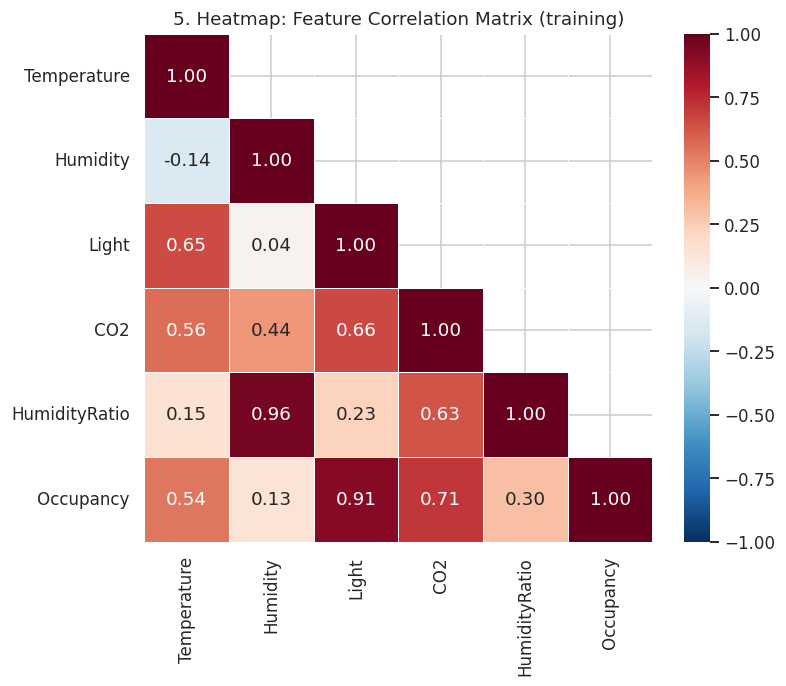

In [12]:
# Plot 5 — Correlation heatmap
corr_all = train[SENSORS + ["Occupancy"]].corr()
plt.figure(figsize=(7.5, 6))
sns.heatmap(corr_all, mask=np.triu(np.ones_like(corr_all, dtype=bool), k=1), annot=True, fmt=".2f",
            cmap="RdBu_r", vmin=-1, vmax=1, linewidths=.5, square=True)
plt.title("5. Heatmap: Feature Correlation Matrix (training)")
save("05_heatmap_correlation"); plt.show()

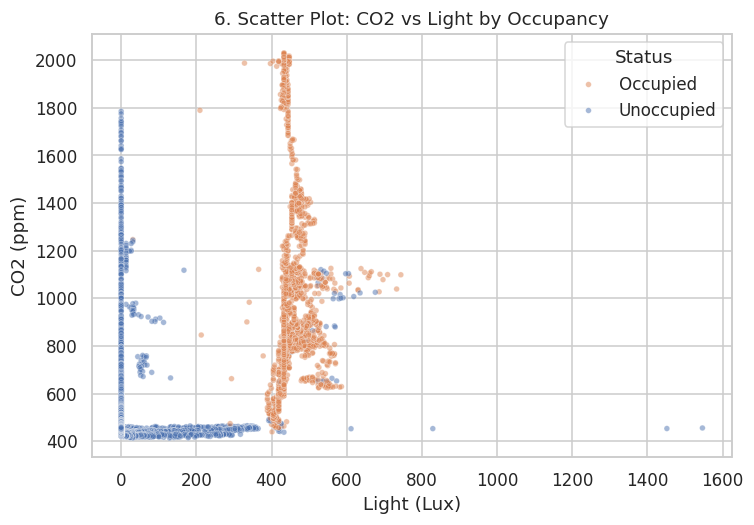

In [13]:
# Plot 6 — Scatter plot: Light vs CO2
plt.figure(figsize=(7.5, 5))
sns.scatterplot(data=train.assign(Status=train["Occupancy"].map(OCC_LABELS)), x="Light", y="CO2", hue="Status",
                palette={"Unoccupied": "#4c72b0", "Occupied": "#dd8452"}, alpha=.5, s=14)
plt.title("6. Scatter Plot: CO2 vs Light by Occupancy"); plt.xlabel("Light (Lux)"); plt.ylabel("CO2 (ppm)")
save("06_scatterplot_light_co2"); plt.show()

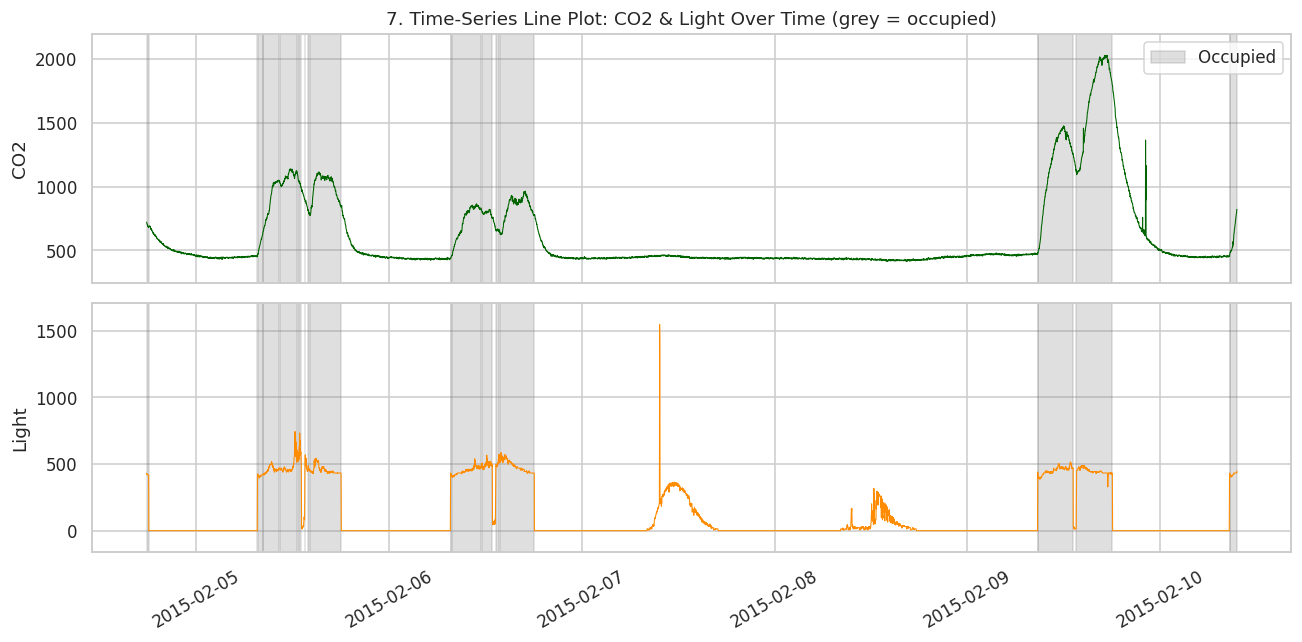

In [14]:
# Plot 7 — Time-series line plot: CO2 and Light with occupied periods shaded
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, col, color in zip(axes, ["CO2", "Light"], ["darkgreen", "darkorange"]):
    ax.plot(train["date"], train[col], color=color, lw=.7)
    ax.fill_between(train["date"], 0, 1, where=train["Occupancy"].values == 1, color="grey", alpha=.25,
                    transform=ax.get_xaxis_transform(), label="Occupied")
    ax.set_ylabel(col)
axes[0].legend(loc="upper right"); axes[0].set_title("7. Time-Series Line Plot: CO2 & Light Over Time (grey = occupied)")
plt.xticks(rotation=30); plt.tight_layout()
save("07_lineplot_timeseries"); plt.show()

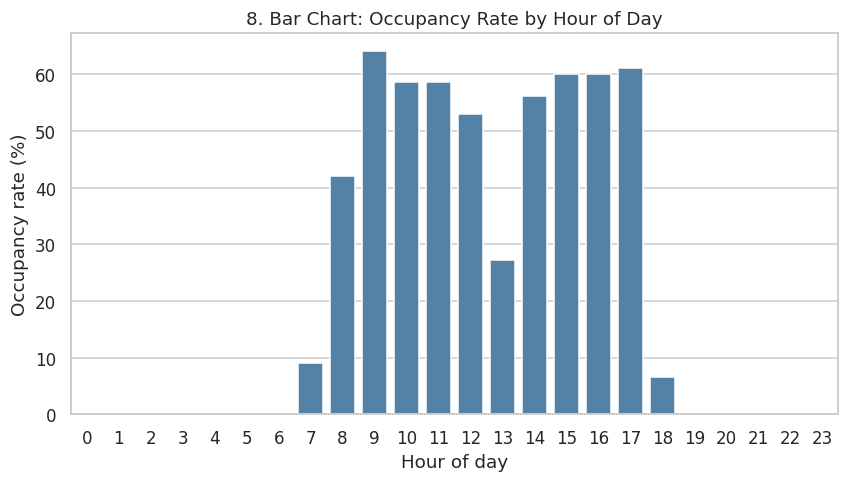

Peak hours: {9: 64.1, 17: 61.2, 15: 60.0}


In [15]:
# Plot 8 — Bar chart: hourly occupancy rate
hourly = (train.groupby("Hour")["Occupancy"].mean() * 100)
plt.figure(figsize=(9, 4.5))
sns.barplot(x=hourly.index, y=hourly.values, color="steelblue")
plt.xlabel("Hour of day"); plt.ylabel("Occupancy rate (%)"); plt.title("8. Bar Chart: Occupancy Rate by Hour of Day")
save("08_barplot_hourly_occupancy"); plt.show()
print("Peak hours:", hourly.sort_values(ascending=False).head(3).round(1).to_dict())

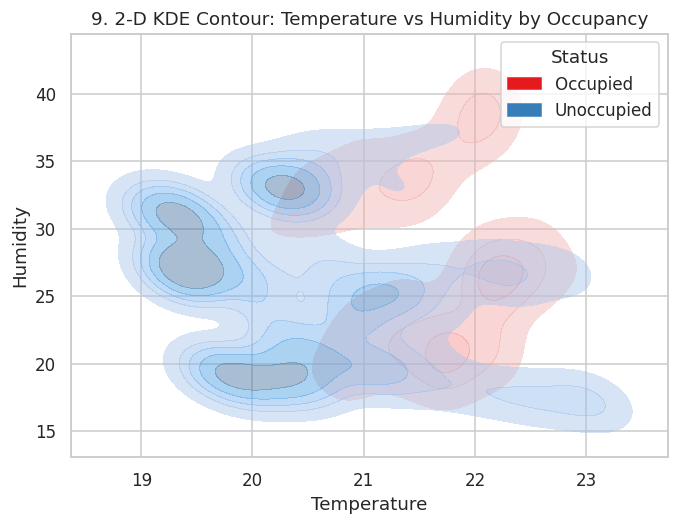

In [16]:
# Plot 9 — 2-D KDE contour: Temperature vs Humidity
plt.figure(figsize=(7, 5))
sns.kdeplot(data=train.assign(Status=train["Occupancy"].map(OCC_LABELS)), x="Temperature", y="Humidity", hue="Status",
            fill=True, alpha=.45, palette="Set1", levels=6)
plt.title("9. 2-D KDE Contour: Temperature vs Humidity by Occupancy")
save("09_kde2d_temp_humidity"); plt.show()

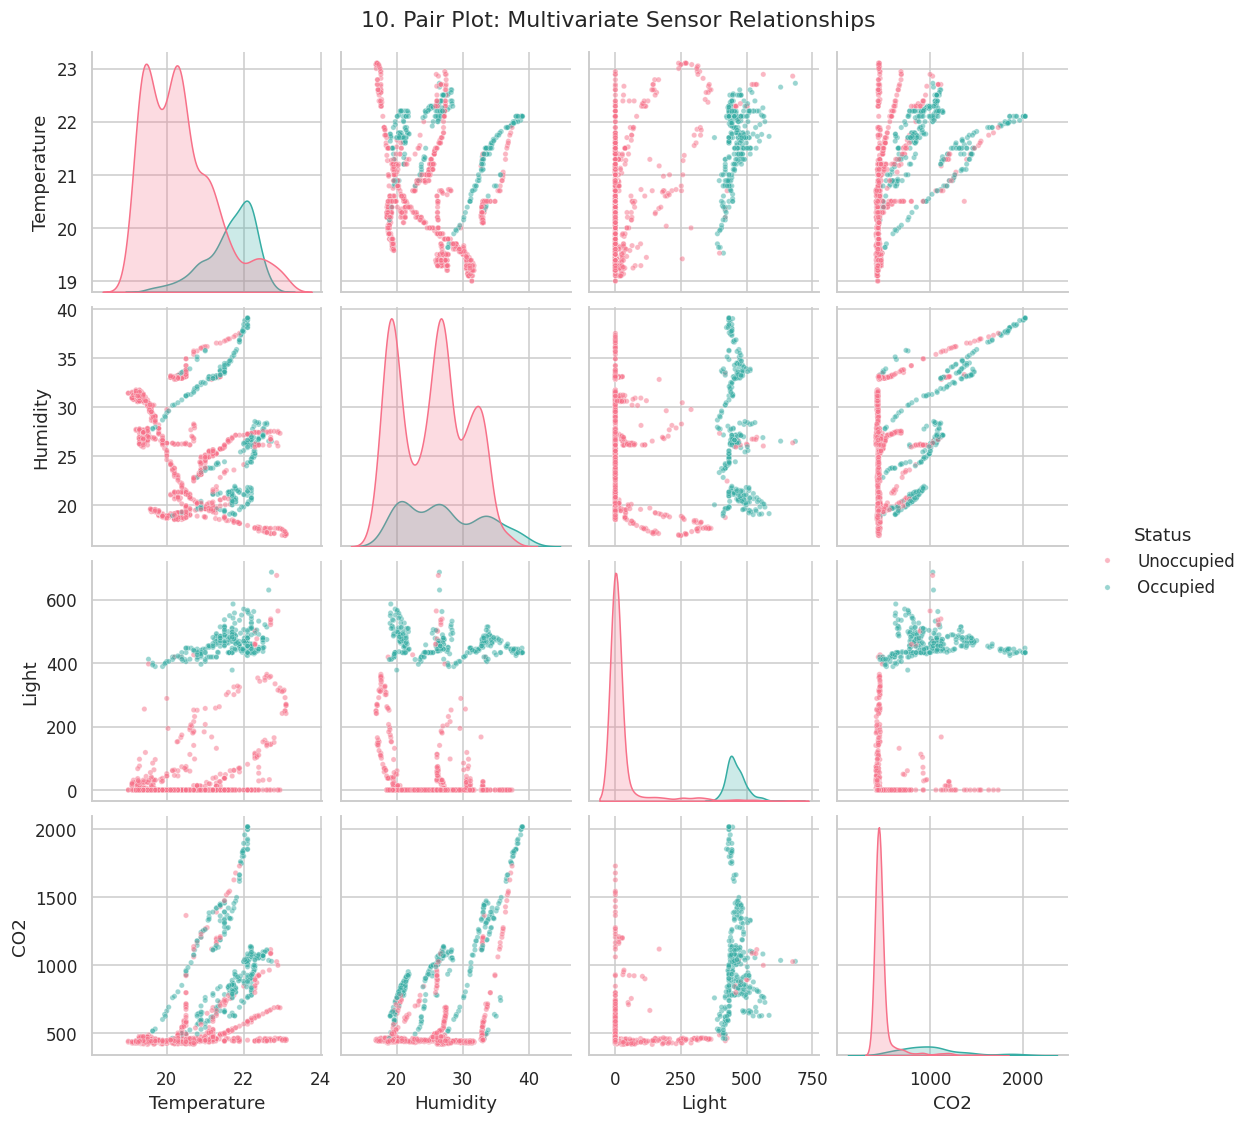

In [17]:
# Plot 10 — Pair plot
sample = train[["Temperature", "Humidity", "Light", "CO2", "Occupancy"]].sample(1500, random_state=RANDOM_STATE)
sample["Status"] = sample.pop("Occupancy").map(OCC_LABELS)
pg = sns.pairplot(sample, hue="Status", palette="husl", diag_kind="kde", plot_kws={"alpha": .5, "s": 12})
pg.fig.suptitle("10. Pair Plot: Multivariate Sensor Relationships", y=1.02)
pg.savefig("plots/10_pairplot_sensors.png"); plt.show()

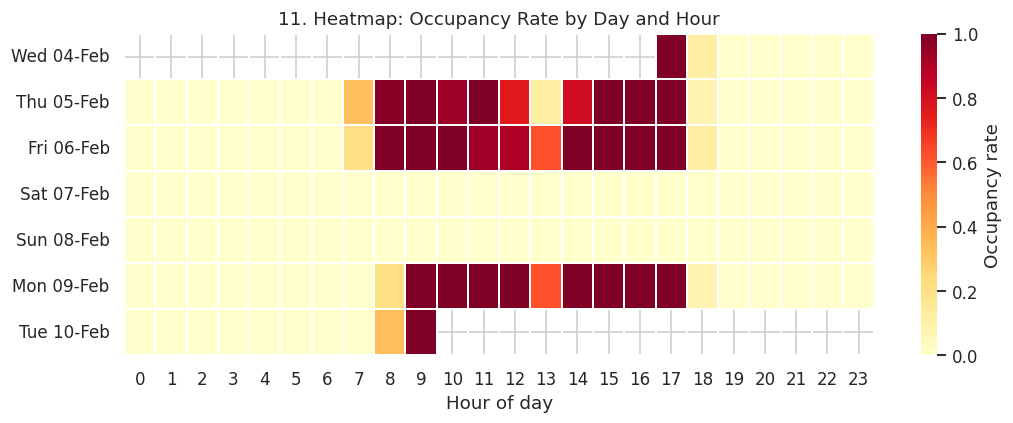

In [18]:
# Plot 11 — Heatmap: occupancy rate by day x hour
tmp = train.assign(Day=train["date"].dt.strftime("%a %d-%b"))
pivot = tmp.pivot_table(index="Day", columns="Hour", values="Occupancy", aggfunc="mean")
pivot = pivot.reindex(tmp.drop_duplicates("Day")["Day"])
plt.figure(figsize=(11, 3.8))
sns.heatmap(pivot, cmap="YlOrRd", vmin=0, vmax=1, linewidths=.3, cbar_kws={"label": "Occupancy rate"})
plt.title("11. Heatmap: Occupancy Rate by Day and Hour"); plt.xlabel("Hour of day"); plt.ylabel("")
save("11_heatmap_day_hour"); plt.show()

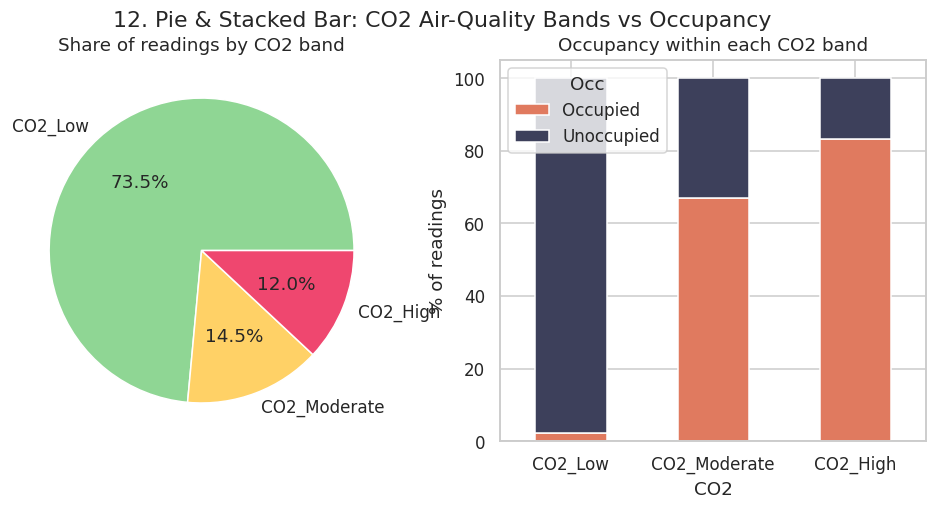

In [19]:
# Plot 12 — Pie chart: CO2 air-quality band shares, and occupied share within each band
band = arm_df["CO2"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
band.value_counts().reindex(["CO2_Low", "CO2_Moderate", "CO2_High"]).plot.pie(
    ax=axes[0], autopct="%1.1f%%", colors=["#8fd694", "#ffd166", "#ef476f"], ylabel="")
axes[0].set_title("Share of readings by CO2 band")
(pd.crosstab(band, arm_df["Occ"], normalize="index") * 100).reindex(["CO2_Low", "CO2_Moderate", "CO2_High"]).plot.bar(
    stacked=True, ax=axes[1], color=["#e07a5f", "#3d405b"], rot=0)
axes[1].set_ylabel("% of readings"); axes[1].set_title("Occupancy within each CO2 band")
plt.suptitle("12. Pie & Stacked Bar: CO2 Air-Quality Bands vs Occupancy")
save("12_pie_co2_bands"); plt.show()

## 4. Predictive analytics
### 4.1 Association rules — Apriori
**Assumed parameters:** minimum support = **0.10**, minimum confidence = **0.80**. Rules with lift > 1.2 are treated as *non-trivial* (lift ≈ 1 means no real association).

In [20]:
MIN_SUPPORT, MIN_CONFIDENCE, MIN_LIFT = 0.10, 0.80, 1.2

arm_enc = pd.get_dummies(arm_df, prefix="", prefix_sep="").astype(bool)
print(f"Transactions: {arm_enc.shape[0]}, distinct items: {arm_enc.shape[1]}")
print(f"Apriori parameters -> min_support={MIN_SUPPORT}, min_confidence={MIN_CONFIDENCE}, min_lift={MIN_LIFT}")

freq_itemsets = apriori(arm_enc, min_support=MIN_SUPPORT, use_colnames=True)
freq_itemsets["size"] = freq_itemsets["itemsets"].apply(len)
print(f"\nFrequent itemsets found: {len(freq_itemsets)}")
display(freq_itemsets.groupby("size").size().rename("count").to_frame().T)

rules_all = association_rules(freq_itemsets, metric="confidence", min_threshold=MIN_CONFIDENCE)
rules_all["rule"] = rules_all.apply(lambda r: f"{', '.join(sorted(r['antecedents']))}  =>  {', '.join(sorted(r['consequents']))}", axis=1)
rules_ap = rules_all[rules_all["lift"] >= MIN_LIFT].sort_values(["lift", "confidence", "support"], ascending=False).reset_index(drop=True)
print(f"Association rules (conf >= {MIN_CONFIDENCE}): {len(rules_all)}  | non-trivial (lift >= {MIN_LIFT}): {len(rules_ap)}")

show = ["rule", "support", "confidence", "lift"]
print("\n--- TOP 15 RULES BY LIFT ---")
display(rules_ap[show].head(15).round(4))

occ_rules = rules_ap[rules_ap["consequents"] == frozenset({"Occupied"})]
unocc_rules = rules_ap[rules_ap["consequents"] == frozenset({"Unoccupied"})]
print(f"\n--- TOP RULES THAT PREDICT 'Occupied'   ({len(occ_rules)} rules) ---")
display(occ_rules[show].head(10).round(4))
print(f"--- TOP RULES THAT PREDICT 'Unoccupied' ({len(unocc_rules)} rules) ---")
display(unocc_rules[show].head(10).round(4))

Transactions: 8143, distinct items: 20
Apriori parameters -> min_support=0.1, min_confidence=0.8, min_lift=1.2

Frequent itemsets found: 278


size,1,2,3,4,5,6
count,20,73,96,64,22,3


Association rules (conf >= 0.8): 595  | non-trivial (lift >= 1.2): 571

--- TOP 15 RULES BY LIFT ---


,rule,support,confidence,lift
0,"Afternoon, Occupied => Light_Bright, Temp_Warm",0.1169,0.9948,5.3931
1,"Afternoon, Occupied, Weekday => Light_Bright...",0.1169,0.9948,5.3931
2,"Afternoon, Occupied => Light_Bright, Temp_Wa...",0.1169,0.9948,5.3931
3,"Afternoon, Light_Bright => Occupied, Temp_Warm",0.1169,0.9389,5.3165
4,"Afternoon, Light_Bright, Weekday => Occupied...",0.1169,0.9389,5.3165
5,"Afternoon, Light_Bright => Occupied, Temp_Wa...",0.1169,0.9389,5.3165
6,"Afternoon, Weekday => Light_Bright, Temp_Warm",0.1245,0.9311,5.0481
7,"Afternoon, Weekday => Occupied, Temp_Warm",0.1175,0.8788,4.9763
8,"Afternoon, Weekday => Light_Bright, Occupied...",0.1169,0.8742,4.9746
9,"Light_Bright, Temp_Warm => Occupied",0.1757,0.9527,4.4870



--- TOP RULES THAT PREDICT 'Occupied'   (10 rules) ---


,rule,support,confidence,lift
9,"Light_Bright, Temp_Warm => Occupied",0.1757,0.9527,4.4870
10,"Light_Bright, Temp_Warm, Weekday => Occupied",0.1757,0.9527,4.4870
17,"Light_Bright, Weekday => Occupied",0.2112,0.9524,4.4854
24,Light_Bright => Occupied,0.2112,0.9503,4.4755
30,"Afternoon, Light_Bright => Occupied",0.1169,0.9389,4.4217
31,"Afternoon, Light_Bright, Temp_Warm => Occupied",0.1169,0.9389,4.4217
32,"Afternoon, Light_Bright, Weekday => Occupied",0.1169,0.9389,4.4217
34,"Afternoon, Light_Bright, Temp_Warm, Weekday =...",0.1169,0.9389,4.4217
38,"Afternoon, Weekday => Occupied",0.1175,0.8788,4.1388
39,"Afternoon, Temp_Warm, Weekday => Occupied",0.1175,0.8788,4.1388


--- TOP RULES THAT PREDICT 'Unoccupied' (99 rules) ---


,rule,support,confidence,lift
450,Light_Off => Unoccupied,0.6337,1.0,1.2696
451,"CO2_Low, Light_Off => Unoccupied",0.5831,1.0,1.2696
452,"Light_Off, Weekday => Unoccupied",0.4146,1.0,1.2696
453,"CO2_Low, Light_Off, Weekday => Unoccupied",0.3640,1.0,1.2696
454,Weekend => Unoccupied,0.3537,1.0,1.2696
455,"CO2_Low, Weekend => Unoccupied",0.3537,1.0,1.2696
456,"Light_Off, Temp_Cool => Unoccupied",0.2743,1.0,1.2696
457,"CO2_Low, Light_Off, Temp_Cool => Unoccupied",0.2743,1.0,1.2696
458,"Light_Off, Temp_Mild => Unoccupied",0.2671,1.0,1.2696
459,Night => Unoccupied,0.2653,1.0,1.2696


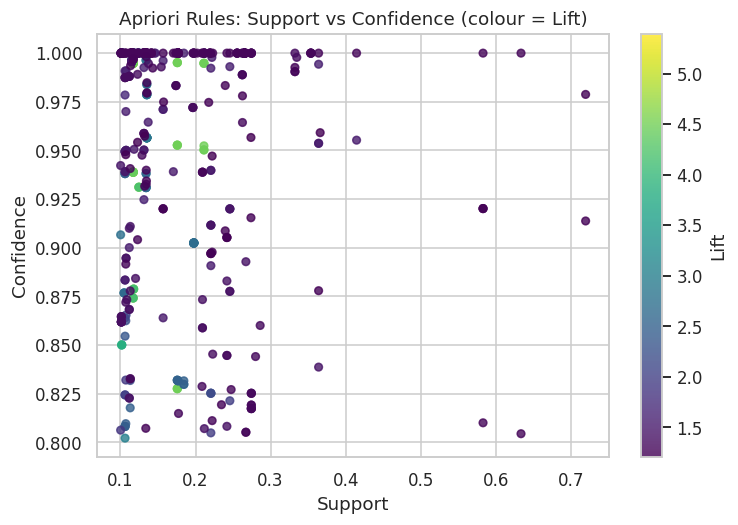

In [21]:
# Support-confidence scatter coloured by lift
plt.figure(figsize=(7.5, 5))
sc = plt.scatter(rules_ap["support"], rules_ap["confidence"], c=rules_ap["lift"], cmap="viridis", s=25, alpha=.8)
plt.colorbar(sc, label="Lift"); plt.xlabel("Support"); plt.ylabel("Confidence")
plt.title("Apriori Rules: Support vs Confidence (colour = Lift)")
save("13_apriori_support_confidence"); plt.show()

### 4.2 Decision Tree classification
Hyper-parameters (criterion, depth, minimum leaf size) are tuned by **leave-one-day-out CV on the training set**. Ties are resolved in favour of the *simplest* tree (smaller depth, larger leaves). The two test sets are used only afterwards.

In [22]:
FEATURES, TARGET = SELECTED, "Occupancy"
X_tr, y_tr = train[FEATURES], train[TARGET]

grid = []
for crit in ["gini", "entropy"]:
    for depth in [2, 3, 4, 5, 6]:
        for leaf in [1, 20, 50, 100]:
            f1, acc = cv_scores(FEATURES, criterion=crit, max_depth=depth, min_samples_leaf=leaf)
            grid.append({"criterion": crit, "max_depth": depth, "min_samples_leaf": leaf,
                         "CV F1": round(f1, 4), "CV Accuracy": round(acc, 4)})
grid = pd.DataFrame(grid).sort_values(["CV F1", "max_depth", "min_samples_leaf", "criterion"],
                                      ascending=[False, True, False, True]).reset_index(drop=True)
print("--- Top 8 hyper-parameter settings (training CV only) ---")
display(grid.head(8))

best = grid.iloc[0]
PARAMS = dict(criterion=best["criterion"], max_depth=int(best["max_depth"]), min_samples_leaf=int(best["min_samples_leaf"]))
print("\nSELECTED PARAMETERS:", PARAMS)

dt_model = DecisionTreeClassifier(random_state=RANDOM_STATE, **PARAMS).fit(X_tr, y_tr)

--- Top 8 hyper-parameter settings (training CV only) ---


,criterion,max_depth,min_samples_leaf,CV F1,CV Accuracy
0,entropy,2,100,0.9466,0.9762
1,gini,2,100,0.9466,0.9762
2,entropy,2,50,0.9466,0.9762
3,gini,2,50,0.9466,0.9762
4,entropy,3,100,0.9466,0.9762
5,gini,3,100,0.9466,0.9762
6,entropy,3,50,0.9466,0.9762
7,gini,3,50,0.9466,0.9762



SELECTED PARAMETERS: {'criterion': 'entropy', 'max_depth': 2, 'min_samples_leaf': 100}


=== Test Set 1 (datatest.txt) ===
                precision    recall  f1-score   support

Unoccupied (0)     0.9982    0.9681    0.9829      1693
  Occupied (1)     0.9472    0.9969    0.9714       972

      accuracy                         0.9786      2665
     macro avg     0.9727    0.9825    0.9772      2665
  weighted avg     0.9796    0.9786    0.9787      2665

ROC-AUC: 0.9827

=== Test Set 2 (datatest2.txt) ===
                precision    recall  f1-score   support

Unoccupied (0)     0.9984    0.9929    0.9956      7703
  Occupied (1)     0.9737    0.9941    0.9838      2049

      accuracy                         0.9931      9752
     macro avg     0.9861    0.9935    0.9897      9752
  weighted avg     0.9932    0.9931    0.9932      9752

ROC-AUC: 0.9956



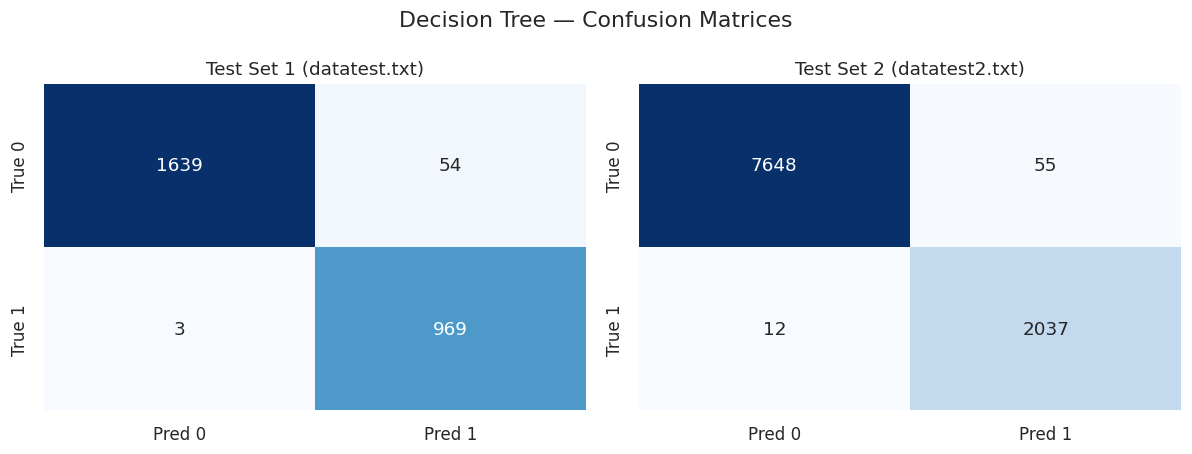

--- PERFORMANCE MEASURES (final model) ---


,Accuracy,Precision,Recall,F1,ROC_AUC
Test Set 1 (datatest.txt),0.9786,0.9472,0.9969,0.9714,0.9827
Test Set 2 (datatest2.txt),0.9931,0.9737,0.9941,0.9838,0.9956


In [23]:
def evaluate(model, df, features):
    X, y = df[features], df[TARGET]
    pred = model.predict(X); proba = model.predict_proba(X)[:, 1]
    return dict(Accuracy=accuracy_score(y, pred), Precision=precision_score(y, pred), Recall=recall_score(y, pred),
                F1=f1_score(y, pred), ROC_AUC=roc_auc_score(y, proba)), pred

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
metrics = {}
for ax, (name, df) in zip(axes, [("Test Set 1 (datatest.txt)", test1), ("Test Set 2 (datatest2.txt)", test2)]):
    m, pred = evaluate(dt_model, df, FEATURES); metrics[name] = m
    print(f"=== {name} ===")
    print(classification_report(df[TARGET], pred, target_names=["Unoccupied (0)", "Occupied (1)"], digits=4))
    print(f"ROC-AUC: {m['ROC_AUC']:.4f}\n")
    sns.heatmap(confusion_matrix(df[TARGET], pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
    ax.set_title(name)
plt.suptitle("Decision Tree — Confusion Matrices"); plt.tight_layout()
save("14_confusion_matrices"); plt.show()

print("--- PERFORMANCE MEASURES (final model) ---")
display(pd.DataFrame(metrics).T.round(4))

In [24]:
# Ablation (for the report): trained on TRAIN only, evaluated on both tests
def fit_eval(features, **kw):
    m = DecisionTreeClassifier(random_state=RANDOM_STATE, **kw).fit(train[features], train[TARGET])
    used = [f for f, i in zip(features, m.feature_importances_) if i > 0]
    out = {f"Acc {n}": round(accuracy_score(d[TARGET], m.predict(d[features])), 4) for n, d in [("Test-1", test1), ("Test-2", test2)]}
    out["Features actually used"] = ", ".join(used)
    return out

abl = {
    "Light + CO2 (selected, tuned)": fit_eval(FEATURES, **PARAMS),
    "Light only (tuned)": fit_eval(["Light"], **PARAMS),
    "All sensors + Hour (tuned)": fit_eval(["Temperature", "Humidity", "Light", "CO2", "Hour"], **PARAMS),
    "Temperature + Humidity + CO2 (tuned)": fit_eval(["Temperature", "Humidity", "CO2"], **PARAMS),
    "5 features, entropy, depth 4, untuned": fit_eval(["Temperature", "Humidity", "Light", "CO2", "Hour"], criterion="entropy", max_depth=4),
}
abl["Majority-class baseline"] = {f"Acc {n}": round(1 - d[TARGET].mean(), 4) for n, d in [("Test-1", test1), ("Test-2", test2)]} | {"Features actually used": "-"}
print("--- Ablation: effect of feature choice / tuning on test accuracy ---")
display(pd.DataFrame(abl).T)
used = [f for f, i in zip(FEATURES, dt_model.feature_importances_) if i > 0]
print(f"Features actually used by the final tree: {used}  (importances: " +
      ", ".join(f"{f}={i:.3f}" for f, i in zip(FEATURES, dt_model.feature_importances_)) + ")")
print("Reading: after tuning, a single Light split family already separates the classes; CO2 never improves the CV score, so a "
      "simple, interpretable tree is the best-supported choice. Dropping tuning / adding noisy features costs accuracy.")

--- Ablation: effect of feature choice / tuning on test accuracy ---


,Acc Test-1,Acc Test-2,Features actually used
"Light + CO2 (selected, tuned)",0.9786,0.9931,Light
Light only (tuned),0.9786,0.9931,Light
All sensors + Hour (tuned),0.9786,0.9931,"Temperature, Light"
Temperature + Humidity + CO2 (tuned),0.8315,0.7933,"Temperature, CO2"
"5 features, entropy, depth 4, untuned",0.9325,0.8672,"Temperature, Humidity, Light, CO2, Hour"
Majority-class baseline,0.6353,0.7899,-


Features actually used by the final tree: ['Light']  (importances: Light=1.000, CO2=0.000)
Reading: after tuning, a single Light split family already separates the classes; CO2 never improves the CV score, so a simple, interpretable tree is the best-supported choice. Dropping tuning / adding noisy features costs accuracy.


--- EXTRACTED DECISION-TREE RULES ---

|--- Light <= 365.12
|   |--- Light <= 209.25
|   |   |--- weights: [6062.00, 1.00] class: 0
|   |--- Light >  209.25
|   |   |--- weights: [262.00, 8.00] class: 0
|--- Light >  365.12
|   |--- Light <= 520.30
|   |   |--- weights: [55.00, 1592.00] class: 1
|   |--- Light >  520.30
|   |   |--- weights: [35.00, 128.00] class: 1



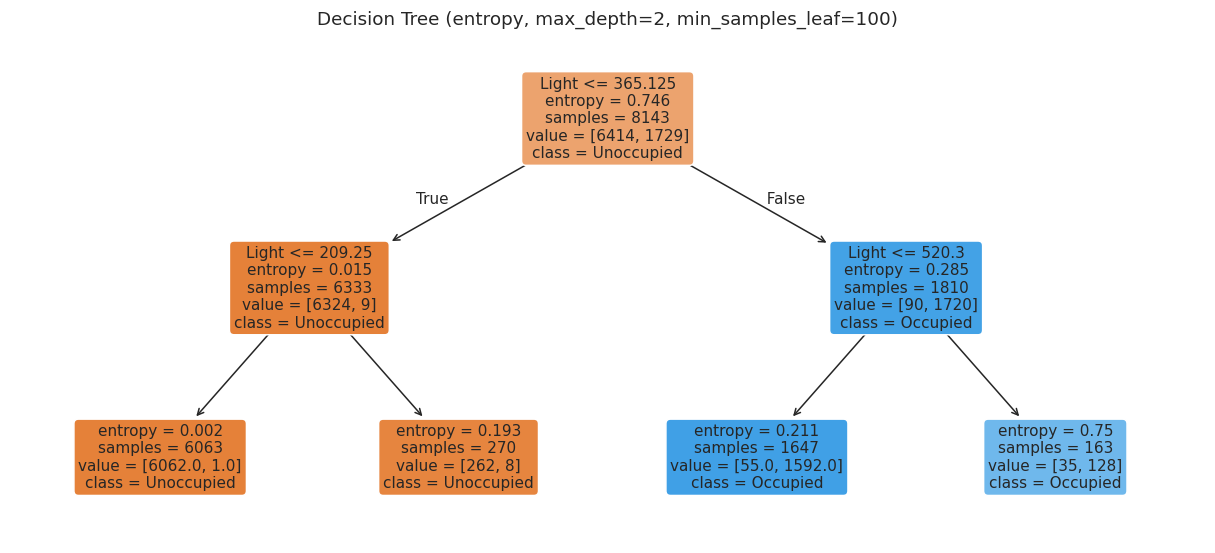

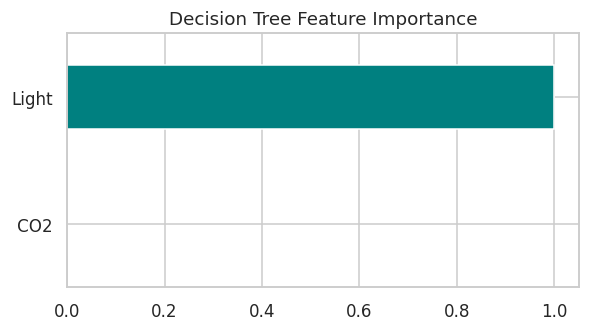

In [25]:
# Explicit IF-THEN rules + tree plot + importance
print("--- EXTRACTED DECISION-TREE RULES ---\n")
print(export_text(dt_model, feature_names=FEATURES, show_weights=True))

plt.figure(figsize=(14, 6))
plot_tree(dt_model, feature_names=FEATURES, class_names=["Unoccupied", "Occupied"], filled=True, rounded=True, fontsize=10, proportion=False)
plt.title(f"Decision Tree ({PARAMS['criterion']}, max_depth={PARAMS['max_depth']}, min_samples_leaf={PARAMS['min_samples_leaf']})")
save("15_decision_tree"); plt.show()

imp = pd.Series(dt_model.feature_importances_, index=FEATURES).sort_values()
plt.figure(figsize=(6, 3)); imp.plot.barh(color="teal"); plt.title("Decision Tree Feature Importance")
save("16_feature_importance"); plt.show()

### 4.3 A-CLOSE — closed frequent itemsets (CFIs) and closed association rules
A-CLOSE (Pasquier et al.) works in three steps:
1. **Generators:** level-wise search for *frequent generators* — itemsets whose support is strictly lower than every one of their subsets.
2. **Closure:** the closure of each generator (all items present in every transaction containing it) gives all **frequent closed itemsets**.
3. **Rule generation** from generators and closed itemsets: the **generic basis** (exact rules, confidence = 1: `g ⇒ closure(g) \ g`) and the **informative basis** (approximate rules `g ⇒ c \ g` with `c` a closed itemset that strictly contains `closure(g)` and confidence ≥ min-confidence).

Same parameters as Apriori: min-support = 0.10, min-confidence = 0.80.

In [26]:
def a_close(enc, min_support):
    n = len(enc); min_count = int(np.ceil(min_support * n - 1e-9))
    items = list(enc.columns)
    tid = {i: enc[i].values for i in items}

    def mask_of(itemset):
        m = np.ones(n, dtype=bool)
        for i in itemset: m &= tid[i]
        return m

    def closure(mask):
        return frozenset(i for i in items if tid[i][mask].all())

    # ---- Step 1: frequent generators, level by level
    gens = {}                       # generator -> (support, closure)
    level = []
    for i in items:
        m = tid[i]; c = m.sum()
        if c >= min_count and c < n:                      # generator: support < support(empty set) = 1
            gens[frozenset([i])] = (c / n, None); level.append(frozenset([i]))
    k = 2
    while level:
        cand = {a | b for a in level for b in level if len(a | b) == k}
        nxt = []
        for cset in cand:
            subs = [frozenset(s) for s in itertools.combinations(cset, k - 1)]
            if not all(s in gens for s in subs):          # every subset must itself be a generator
                continue
            c = mask_of(cset).sum()
            if c >= min_count and all(c / n < gens[s][0] for s in subs):
                gens[cset] = (c / n, None); nxt.append(cset)
        level = nxt; k += 1

    # ---- Step 2: closures -> closed frequent itemsets
    cfis = {}
    for g in list(gens):
        cl = closure(mask_of(g))
        gens[g] = (gens[g][0], cl)
        cfis[cl] = gens[g][0]
    return gens, cfis, mask_of

gens, cfis, mask_of = a_close(arm_enc, MIN_SUPPORT)
n_trans = len(arm_enc)

cfi_df = pd.DataFrame({"itemset": [", ".join(sorted(s)) for s in cfis], "size": [len(s) for s in cfis],
                       "support": list(cfis.values())}).sort_values(["support", "size"], ascending=[False, False]).reset_index(drop=True)
print(f"A-CLOSE parameters -> min_support={MIN_SUPPORT}, min_confidence={MIN_CONFIDENCE}")
print(f"Frequent generators        : {len(gens)}")
print(f"Frequent itemsets (Apriori): {len(freq_itemsets)}")
print(f"Closed frequent itemsets   : {len(cfis)}  ({100*(1-len(cfis)/len(freq_itemsets)):.1f}% reduction)\n")
print("--- TOP 20 CLOSED FREQUENT ITEMSETS ---")
display(cfi_df.head(20).round(4))

A-CLOSE parameters -> min_support=0.1, min_confidence=0.8
Frequent generators        : 143
Frequent itemsets (Apriori): 278
Closed frequent itemsets   : 140  (49.6% reduction)

--- TOP 20 CLOSED FREQUENT ITEMSETS ---


,itemset,size,support
0,Unoccupied,1,0.7877
1,CO2_Low,1,0.7354
2,"CO2_Low, Unoccupied",2,0.7198
3,Weekday,1,0.6463
4,"Light_Off, Unoccupied",2,0.6337
5,"CO2_Low, Light_Off, Unoccupied",3,0.5831
6,"Unoccupied, Weekday",2,0.4340
7,"Light_Off, Unoccupied, Weekday",3,0.4146
8,"CO2_Low, Weekday",2,0.3817
9,"CO2_Low, Unoccupied, Weekday",3,0.3661


In [27]:
# Correctness checks (will raise AssertionError if anything is wrong)
fs_support = {s: sup for s, sup in zip(freq_itemsets["itemsets"], freq_itemsets["support"])}

# (1) CFIs from A-CLOSE == itemsets with no proper superset of equal support (brute force on Apriori output)
brute = {s for s, v in fs_support.items() if not any(s < t and abs(fs_support[t] - v) < 1e-12 for t in fs_support)}
assert brute == set(cfis), "A-CLOSE CFIs differ from brute-force closed itemsets"

# (2) Losslessness: support of EVERY frequent itemset can be recovered from its closure
for s, v in fs_support.items():
    cl = frozenset(i for i in arm_enc.columns if arm_enc[i].values[mask_of(s)].all())
    assert abs(cfis[cl] - v) < 1e-12
print(f"OK: {len(cfis)} CFIs match brute-force closed itemsets, and all {len(fs_support)} frequent-itemset supports are recoverable from the CFIs.")

OK: 140 CFIs match brute-force closed itemsets, and all 278 frequent-itemset supports are recoverable from the CFIs.


In [28]:
# ---------- Closed association rules (generic basis + informative basis) ----------
def sup_of(itemset): return mask_of(itemset).mean()

rows = []
for g, (sg, cl) in gens.items():
    # Exact rules (generic basis): g => closure(g) \ g, confidence = 1
    if cl != g:
        cons = cl - g
        rows.append((g, cons, sg, 1.0, "exact"))
    # Approximate rules (informative basis): g => c \ g for closed c strictly containing closure(g)
    for c, sc in cfis.items():
        if cl < c and sc / sg >= MIN_CONFIDENCE:
            rows.append((g, c - g, sc, sc / sg, "approximate"))

closed_rules = pd.DataFrame(rows, columns=["antecedents", "consequents", "support", "confidence", "type"])
closed_rules["lift"] = closed_rules.apply(lambda r: r["confidence"] / sup_of(r["consequents"]), axis=1)
closed_rules["rule"] = closed_rules.apply(lambda r: f"{', '.join(sorted(r['antecedents']))}  =>  {', '.join(sorted(r['consequents']))}", axis=1)

# verify every rule's support / confidence directly from the data
for _, r in closed_rules.iterrows():
    union = r["antecedents"] | r["consequents"]
    assert abs(sup_of(union) - r["support"]) < 1e-9 and abs(sup_of(union) / sup_of(r["antecedents"]) - r["confidence"]) < 1e-9
print("OK: support & confidence of all closed rules verified directly on the data.")

closed_nt = closed_rules[closed_rules["lift"] >= MIN_LIFT].sort_values(["lift", "confidence", "support"], ascending=False).reset_index(drop=True)
print(f"\nClosed association rules (conf >= {MIN_CONFIDENCE}): {len(closed_rules)}  "
      f"(exact: {(closed_rules.type=='exact').sum()}, approximate: {(closed_rules.type=='approximate').sum()})")
print(f"Non-trivial (lift >= {MIN_LIFT}): {len(closed_nt)}   vs Apriori non-trivial rules: {len(rules_ap)} "
      f"-> {100*(1-len(closed_nt)/len(rules_ap)):.1f}% fewer (all frequent-itemset supports stay recoverable from the CFIs)")

show2 = ["rule", "type", "support", "confidence", "lift"]
print("\n--- TOP 15 CLOSED ASSOCIATION RULES (by lift) ---")
display(closed_nt[show2].head(15).round(4))

c_occ = closed_nt[closed_nt["consequents"].apply(lambda s: "Occupied" in s)]
c_unocc = closed_nt[closed_nt["consequents"].apply(lambda s: "Unoccupied" in s)]
print(f"--- CLOSED RULES WITH 'Occupied' IN THE CONSEQUENT ({len(c_occ)}) ---")
display(c_occ[show2].head(10).round(4))
print(f"--- CLOSED RULES WITH 'Unoccupied' IN THE CONSEQUENT ({len(c_unocc)}) ---")
display(c_unocc[show2].head(10).round(4))

closed_rules.drop(columns=["rule"]).assign(
    antecedents=closed_rules["antecedents"].apply(lambda s: ", ".join(sorted(s))),
    consequents=closed_rules["consequents"].apply(lambda s: ", ".join(sorted(s)))
).to_csv("processed_data/closed_association_rules.csv", index=False)
cfi_df.to_csv("processed_data/closed_frequent_itemsets.csv", index=False)
rules_ap.drop(columns=["rule"]).assign(
    antecedents=rules_ap["antecedents"].apply(lambda s: ", ".join(sorted(s))),
    consequents=rules_ap["consequents"].apply(lambda s: ", ".join(sorted(s)))
).to_csv("processed_data/apriori_rules.csv", index=False)

OK: support & confidence of all closed rules verified directly on the data.

Closed association rules (conf >= 0.8): 242  (exact: 67, approximate: 175)
Non-trivial (lift >= 1.2): 225   vs Apriori non-trivial rules: 571 -> 60.6% fewer (all frequent-itemset supports stay recoverable from the CFIs)

--- TOP 15 CLOSED ASSOCIATION RULES (by lift) ---


,rule,type,support,confidence,lift
0,"Afternoon, Occupied => Light_Bright, Temp_Wa...",approximate,0.1169,0.9948,5.3931
1,"Afternoon, Light_Bright => Occupied, Temp_Wa...",approximate,0.1169,0.9389,5.3165
2,"Afternoon, Weekday => Light_Bright, Temp_Warm",approximate,0.1245,0.9311,5.0481
3,"Afternoon, Weekday => Occupied, Temp_Warm",approximate,0.1175,0.8788,4.9763
4,"Afternoon, Weekday => Light_Bright, Occupied...",approximate,0.1169,0.8742,4.9746
5,"Light_Bright, Temp_Warm => Occupied, Weekday",approximate,0.1757,0.9527,4.4870
6,"Occupied => Light_Bright, Temp_Warm, Weekday",approximate,0.1757,0.8276,4.4870
7,"Occupied, Temp_Warm => Light_Bright, Weekday",approximate,0.1757,0.9951,4.4869
8,"Occupied => Light_Bright, Weekday",approximate,0.2112,0.9948,4.4854
9,"Light_Bright, Weekday => Occupied",approximate,0.2112,0.9524,4.4854


--- CLOSED RULES WITH 'Occupied' IN THE CONSEQUENT (6) ---


,rule,type,support,confidence,lift
1,"Afternoon, Light_Bright => Occupied, Temp_Wa...",approximate,0.1169,0.9389,5.3165
3,"Afternoon, Weekday => Occupied, Temp_Warm",approximate,0.1175,0.8788,4.9763
4,"Afternoon, Weekday => Light_Bright, Occupied...",approximate,0.1169,0.8742,4.9746
5,"Light_Bright, Temp_Warm => Occupied, Weekday",approximate,0.1757,0.9527,4.4870
9,"Light_Bright, Weekday => Occupied",approximate,0.2112,0.9524,4.4854
10,"Light_Bright => Occupied, Weekday",approximate,0.2112,0.9503,4.4755


--- CLOSED RULES WITH 'Unoccupied' IN THE CONSEQUENT (113) ---


,rule,type,support,confidence,lift
16,"Hum_Humid, Light_Off, Weekend => CO2_Low, Te...",exact,0.1014,1.0000,3.0081
22,"Hum_Humid, Weekend => CO2_Low, Temp_Cool, Un...",approximate,0.1351,0.9565,2.8773
23,"Hum_Humid, Light_Off, Temp_Cool => CO2_Low, ...",exact,0.1014,1.0000,2.8274
26,"CO2_Low, Light_Dim => Unoccupied, Weekend",approximate,0.1341,0.9964,2.8171
27,"CO2_Low, Hum_Humid, Temp_Cool => Unoccupied,...",approximate,0.1351,0.9839,2.7819
28,"Hum_Humid, Temp_Cool => CO2_Low, Unoccupied,...",approximate,0.1351,0.9786,2.7671
29,"Night, Temp_Mild => CO2_Low, Light_Off, Unoc...",approximate,0.1148,0.9957,2.7356
31,"Light_Off, Weekend => CO2_Low, Temp_Cool, Un...",approximate,0.1977,0.9025,2.7147
32,"CO2_Low, Hum_Dry, Light_Off, Weekday => Temp...",approximate,0.1061,0.8082,2.7017
34,"Light_Dim => CO2_Low, Unoccupied, Weekend",approximate,0.1341,0.9309,2.6322


,Frequent itemsets / CFIs,Rules (conf >= 0.80),Non-trivial rules (lift >= 1.2)
Apriori,278,595,571
A-CLOSE,140,242,225


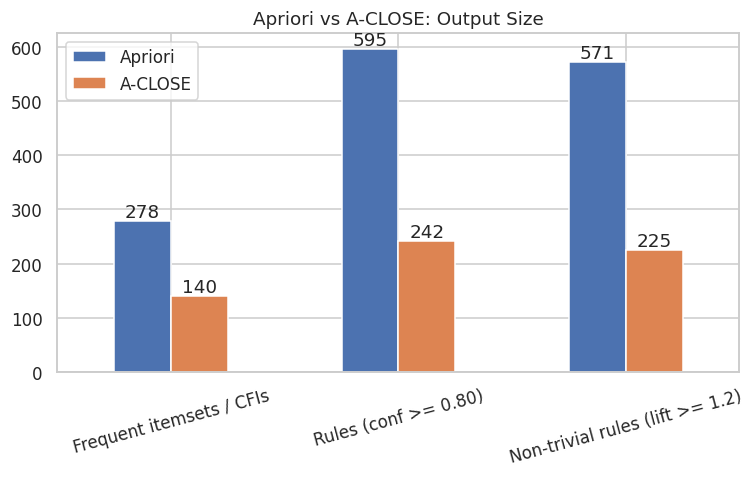

All outputs saved: plots/ (PNG) and processed_data/ (CSV).


In [30]:
# Apriori vs A-CLOSE comparison
comp = pd.DataFrame({
    "Frequent itemsets / CFIs": [len(freq_itemsets), len(cfis)],
    "Rules (conf >= 0.80)": [len(rules_all), len(closed_rules)],
    "Non-trivial rules (lift >= 1.2)": [len(rules_ap), len(closed_nt)],
}, index=["Apriori", "A-CLOSE"])
display(comp)
ax = comp.T.plot.bar(figsize=(8, 4), rot=15, color=["#4c72b0", "#dd8452"])
for c in ax.containers: ax.bar_label(c)
plt.title("Apriori vs A-CLOSE: Output Size"); save("17_apriori_vs_aclose"); plt.show()
print("All outputs saved: plots/ (PNG) and processed_data/ (CSV).")